# 73: Explore PC and Environmental Factor Relationship

This notebook explores the relationship between Tokyo Bay PC1 and environmental factors:
- Summer 1 Density
- Summer 2 DOC
- Summer 2 TN

For each parameter, we plot the time-series graph of the top 10 contributing stations for PC1, matching the plot layout with script `step4` `process12`.

In [1]:
# --- 1. Imports ---
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import gsw
import sys
from pathlib import Path
import os

# Ensure we can import from 'utils' directory
project_root = Path("../").resolve()
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from utils.paths import ProjectPaths
from utils.data_loader import load_and_process_data

# Apply global project style
plt.style.use(str(ProjectPaths.PROJECT_ROOT / 'project_style.mplstyle'))

## 2. Output Directory Setup

In [2]:
# Define the name of this notebook for output folder creation
notebook_name = "73_explore_pc_env_relationship" 

# Setup output directory specific to this sandbox notebook
sandbox_output_dir = ProjectPaths.FIGURES_DIR / "step0_sandbox" / notebook_name
sandbox_output_dir.mkdir(parents=True, exist_ok=True)
print(f"Output directory set to: {sandbox_output_dir}")

Output directory set to: /home/reyha/SIS_Analysis_WSL/figures/step0_sandbox/73_explore_pc_env_relationship


## 3. Data Loading

In [3]:
# 1. Load PC Scores and EOFs for Tokyo Bay
pca_dir = ProjectPaths.PROCESSED_DATA_DIR / 'step4_PCA_analysis' / 'process11_calculate_pca_explained_variance_per_bay_raw' / 'tokyo_bay'
pc_scores = pd.read_csv(pca_dir / 'tokyo_bay_pc_scores.csv', index_col=0)
eof_df = pd.read_csv(pca_dir / 'tokyo_bay_eof_patterns.csv')
eof_df['Station_ID'] = eof_df['Station_ID'].astype(str).str.zfill(8)

var_df = pd.read_csv(pca_dir / 'tokyo_bay_pca_variance.csv')
pc1_var = var_df[var_df['PC'] == 'PC1']['Variance_Pct'].values[0]

# 2. Get top 10 contributing stations for PC1
eof_df['abs_EOF1'] = eof_df['EOF1'].abs()
top10_stations = eof_df.sort_values('abs_EOF1', ascending=False).head(10)['Station_ID'].tolist()
print(f"Top 10 contributing stations for PC1: {top10_stations}")

# 3. Load environmental data
merged_gdf = load_and_process_data(force_reload=False)
merged_gdf['zettaicode'] = merged_gdf['zettaicode'].astype(str).str.zfill(8)

# Calculate density
merged_gdf['density'] = gsw.rho(pd.to_numeric(merged_gdf['salt'], errors='coerce'), 
                                pd.to_numeric(merged_gdf['wtemp'], errors='coerce'), 0) - 1000

Top 10 contributing stations for PC1: ['00000122', '00000124', '00000125', '00000128', '00001212', '00001210', '00001313', '00001230', '00001311', '00001235']
Loading processed data from /home/reyha/SIS_Analysis_WSL/data/processed/merged_gdf.feather...


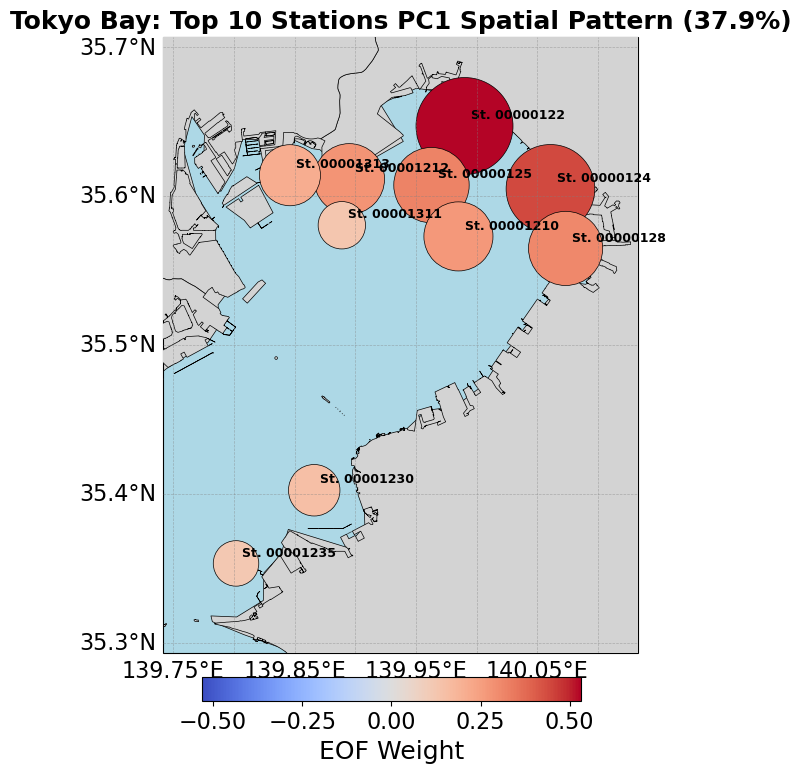

In [4]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import geopandas as gpd
from utils.mapping_config import MappingConfig

division = 'Tokyo Bay'

# 1. Prepare map data using existing variables
station_coords = merged_gdf[['zettaicode', 'latitude', 'longitude']].drop_duplicates('zettaicode').set_index('zettaicode')
top10_eof = eof_df[eof_df['Station_ID'].isin(top10_stations)].set_index('Station_ID')

plot_data = station_coords.loc[top10_eof.index].copy()
plot_data['EOF'] = top10_eof['EOF1'].values

# 2. Setup Figure and Cartopy projection
map_extent = MappingConfig.get_dynamic_extent(division, plot_data=plot_data)
fig_width, fig_height = MappingConfig.get_dynamic_figsize(map_extent, base_width=10)

fig, ax = plt.subplots(figsize=(fig_width, fig_height), subplot_kw={'projection': ccrs.PlateCarree()})
ax.set_facecolor(MappingConfig.COLOR_OCEAN)
ax.add_feature(cfeature.LAND, facecolor=MappingConfig.COLOR_LAND, zorder=MappingConfig.ZORDER_CARTOPY_LAND)
ax.add_feature(cfeature.COASTLINE, linewidth=0.5, zorder=MappingConfig.ZORDER_CARTOPY_COASTLINE)

# 3. Add boundaries
land_boundary_path = ProjectPaths.BOUNDARIES_DIR / "SIS_prefecture_boundaries" / "Tokyobay_boundary.shp"
if land_boundary_path.exists():
    land_boundary = gpd.read_file(land_boundary_path).to_crs("EPSG:4326")
    land_boundary.plot(ax=ax, facecolor=MappingConfig.COLOR_LAND, edgecolor=MappingConfig.COLOR_LAND_EDGE, 
                       linewidth=MappingConfig.LINEWIDTH_LAND, transform=ccrs.PlateCarree(), zorder=MappingConfig.ZORDER_LAND)

# 4. Plot points with dynamic size based on zoom level
vmax = max(abs(plot_data['EOF'].min()), abs(plot_data['EOF'].max()))
zoom_factor = max(4.5 / (map_extent[1] - map_extent[0]), 1.0)

sc = ax.scatter(
    plot_data['longitude'], plot_data['latitude'], c=plot_data['EOF'], cmap='coolwarm',
    vmin=-vmax, vmax=vmax, s=np.maximum(abs(plot_data['EOF']) * 800 * zoom_factor, 50 * zoom_factor), 
    edgecolors='k', linewidths=0.5, transform=ccrs.PlateCarree(), zorder=MappingConfig.ZORDER_OBSERVATIONS
)

for idx, row in plot_data.iterrows():
    ax.text(row['longitude'] + 0.005, row['latitude'] + 0.005, f'St. {idx}', 
            transform=ccrs.PlateCarree(), fontsize=9, fontweight='bold', zorder=MappingConfig.ZORDER_OBSERVATIONS+1)

MappingConfig.apply_gridlines(ax)
ax.set_extent(map_extent, crs=ccrs.PlateCarree())
plt.title(f'{division}: Top 10 Stations PC1 Spatial Pattern ({pc1_var:.1f}%)')

cbar_ax = fig.add_axes([0.25, 0.05, 0.5, 0.03])
fig.colorbar(sc, cax=cbar_ax, orientation='horizontal').set_label('EOF Weight')

plt.savefig(sandbox_output_dir / "tokyo_bay_pc1_top10_eof_map.png", bbox_inches='tight', dpi=300)
plt.show()


## 4. Plotting Time Series

Saved figure to: /home/reyha/SIS_Analysis_WSL/figures/step0_sandbox/73_explore_pc_env_relationship/tokyo_bay_pc1_summer_1_density.png


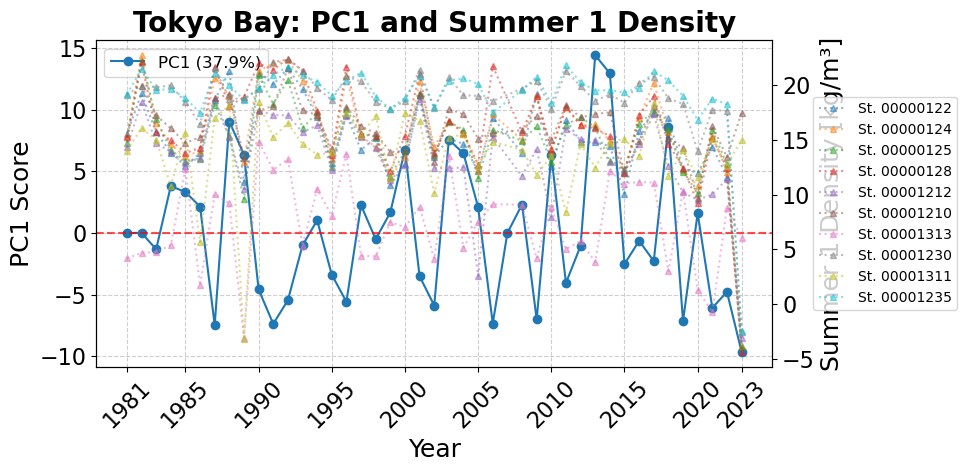

Saved figure to: /home/reyha/SIS_Analysis_WSL/figures/step0_sandbox/73_explore_pc_env_relationship/tokyo_bay_pc1_summer_2_doc.png


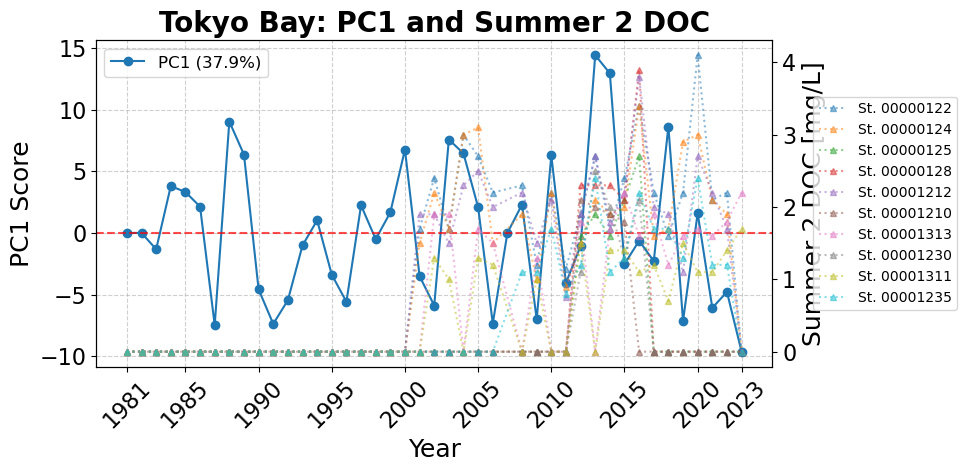

Saved figure to: /home/reyha/SIS_Analysis_WSL/figures/step0_sandbox/73_explore_pc_env_relationship/tokyo_bay_pc1_summer_2_tn.png


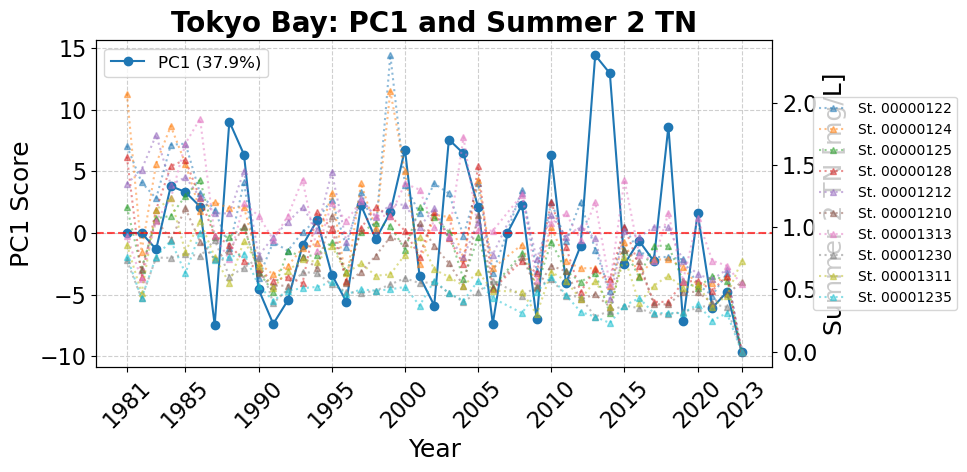

In [5]:
# Define parameters to plot
params = [
    {'name': 'Summer 1 Density', 'season': 'Summer', 'layer': 1, 'col': 'density', 'unit': 'kg/m³'},
    {'name': 'Summer 2 DOC', 'season': 'Summer', 'layer': 2, 'col': 'doc', 'unit': 'mg/L'},
    {'name': 'Summer 2 TN', 'season': 'Summer', 'layer': 2, 'col': 'tn', 'unit': 'mg/L'}
]

# Determine dynamic tick years matching process12
first_year = pc_scores.index[0]
last_year = pc_scores.index[-1]
target_type = type(first_year)
mid_ticks = [target_type(y) for y in range(1985, 2021, 5) if target_type(y) in pc_scores.index]
tick_years = sorted(list(set([first_year] + mid_ticks + [last_year])), key=lambda x: int(x))

for p in params:
    # Filter data for the specific season and layer
    p_data = merged_gdf[(merged_gdf['season'] == p['season']) & 
                        (merged_gdf['saisuipoin'] == p['layer']) &
                        (merged_gdf['zettaicode'].isin(top10_stations))].copy()
    
    p_data[p['col']] = pd.to_numeric(p_data[p['col']], errors='coerce')
    
    # Create plot with same layout as process12
    fig, ax1 = plt.subplots(figsize=(10, 5))
    
    # Plot PC1 on the primary y-axis
    ax1.plot(pc_scores.index, pc_scores['PC1'], marker='o', label=f'PC1 ({pc1_var:.1f}%)', color='tab:blue')
    ax1.axhline(y=0, color='red', linestyle='--', alpha=0.7)
    ax1.set_xlabel('Year')
    ax1.set_ylabel('PC1 Score')
    ax1.set_title(f'Tokyo Bay: PC1 and {p["name"]}', fontsize=20, fontweight='bold')
    
    # Tick settings matching process12
    ax1.set_xticks(tick_years)
    ax1.tick_params(axis='x', rotation=45)
    ax1.grid(True, linestyle='--', alpha=0.6)
    
    # Create secondary y-axis for environmental parameter
    ax2 = ax1.twinx()
    
    # Plot top 10 stations
    colors = plt.cm.tab10(np.linspace(0, 1, 10))
    for i, st in enumerate(top10_stations):
        st_data = p_data[p_data['zettaicode'] == st].groupby('surveyyear')[p['col']].mean().reset_index()
        if not st_data.empty:
            ax2.plot(st_data['surveyyear'], st_data[p['col']], marker='^', markersize=4, alpha=0.5, 
                     color=colors[i], label=f'St. {st}', linestyle=':')
            
    ax2.set_ylabel(f'{p["name"]} [{p["unit"]}]')
    
    # Legends
    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax1.legend(lines1, labels1, loc='upper left', fontsize=12)
    ax2.legend(lines2, labels2, loc='center left', bbox_to_anchor=(1.05, 0.5), fontsize=10)
    
    # Save the figure
    safe_name = p['name'].replace(' ', '_').lower()
    fig_out = sandbox_output_dir / f"tokyo_bay_pc1_{safe_name}.png"
    plt.tight_layout()
    plt.savefig(fig_out, bbox_inches='tight', dpi=300)
    print(f"Saved figure to: {fig_out}")
    
    plt.show()